In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #03 - Statistical Objective Analysis

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using statistical objective analysis.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"
__StudentName__ = 'Austin Portner'

In [2]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

In [3]:
### Read in observations ###
path = 'C:/Users/austi/Desktop/AtSc_Masters_Classes/AtSc_528/Function_Fitting/'
file = 'RAOBs_201903131200.txt'
#path+file

In [4]:
### Set up analysis map with a 21x27 rectangular grid of points ###
# From hw2
lats, lons, hgts = [], [], []

with open(path+file, 'r') as f:
    for line in f:
        parts = line.strip().split(',')
        if len(parts) >=4:
            try:
                lat = float(parts[1])
                lon = float(parts[2])
                hgt = float(parts[3])
                # append valid observation data
                if not np.isnan(hgt):
                    lats.append(lat)
                    lons.append(lon)
                    hgts.append(hgt)
            except ValueError:
                continue

#Conversion to np arrays
obs_lat = np.array(lats)
obs_lon = np.array(lons)
obs_hgt = np.array(hgts)

# Now to setip 21x27 analysis grid
y, x = 27, 21
dx, dy = 1.27, 1.27 #in cm
x0, y0 = 25.0, -15.5 #in cm

# Now to generate 1D vectors and 2D meshgrid
grid_x_1d = x0 + np.arange(x) * dx
grid_y_1d = y0 + np.arange(y) * dy

grid_x_map, grid_y_map = np.meshgrid(grid_x_1d, grid_y_1d, indexing = 'ij')

In [5]:
### convert obs lat/long to x,y ###
# From hw2
lambda_0 = -100.0
phi_0 = 60.0
rho = 6371229.0 
m = 1 / 15000000
R = rho * 100.0 * m

# Angles from lat/lon to radians
lat_rad = np.radians(obs_lat)
lon_rad = np.radians(obs_lon)
lambda_0_rad = np.radians(lambda_0)
phi_0_rad = np.radians(phi_0)

#conversion to cartesian coordinates in cm
sigma_obs = (1.0 + np.sin(phi_0_rad)) / (1.0 + np.sin(lat_rad))
obs_x = R * sigma_obs * np.cos(lat_rad) * np.cos(lon_rad - lambda_0_rad)
obs_y = R * sigma_obs * np.cos(lat_rad) * np.sin(lon_rad - lambda_0_rad)

###*** All of the above code came from previous homeworks***###

In [6]:
# Barnes Analysis

Kd = 10.8844524 # cm^2
re = 12.7775892 # cm

# Background initialization
background = np.zeros_like(grid_x_map)
nx, ny = grid_x_map.shape

# Generating background on 21x27 grid
for i in range(nx):
    for j in range(ny):
        gx = grid_x_map[i, j]
        gy = grid_y_map[i, j]
        
        # squared distance from grid pts to obs
        d_sq = (gx - obs_x)**2 + (gy - obs_y)**2
        valid_mask = d_sq <= re**2
        
        if np.any(valid_mask):
            d_sq_valid = d_sq[valid_mask]
            hgt_valid = obs_hgt[valid_mask]
            
            # Barnes weight function
            weights = np.exp(-d_sq_valid / Kd)
            background[i, j] = np.sum(weights * hgt_valid)/ np.sum(weights)
        else:
            background[i, j] = np.mean(obs_hgt)

# Background values at obs locations
background_obs = np.zeros_like(obs_hgt)
for k in range(len(obs_hgt)):
    ox = obs_x[k]
    oy = obs_y[k]
    
    d_sq = (ox - obs_x)**2 + (oy - obs_y)**2
    valid_mask = d_sq <= re**2
    valid_mask[k] = False
    
    if np.any(valid_mask):
        d_sq_valid = d_sq[valid_mask]
        hgt_valid = obs_hgt[valid_mask]
        weights = np.exp(-d_sq_valid / Kd)
        background_obs[k] = np.sum(weights * hgt_valid) / np.sum(weights)
    else:
        background_obs[k] = obs_hgt[k]

In [7]:
# Now to perform Statistical Objective Analysis

# obs minus background at obs locations aka innovations
innovations = obs_hgt - background_obs
analysis_grid = np.zeros_like(grid_x_map)

for i in range(nx):
    for j in range(ny):
        gx = grid_x_map[i, j]
        gy = grid_y_map[i, j]
        
        # d^2 from grid pt to all obs
        grid_obs_d_sq = (gx - obs_x)**2 + (gy - obs_y)**2
        local_mask = grid_obs_d_sq <= re**2
        
        # No obs in RoI, this falls back to background
        if not np.any(local_mask):
            analysis_grid[i, j] = background[i, j]
            continue
            
        local_indices = np.where(local_mask)[0]
        sub_obs_x = obs_x[local_indices]
        sub_obs_y = obs_y[local_indices]
        sub_innovations = innovations[local_indices]
        
        # building the P matrix - this is correlation between local obs using Kd
        dist_mat_sq = (sub_obs_x[:, None] - sub_obs_x[None, :])**2 + (sub_obs_y[:, None] - sub_obs_y[None, :])**2
        P_matrix = np.exp(-dist_mat_sq / Kd)
        
        # Now to build rho vector - this is correlation between local obs and grid pt using Kd
        grid_obs_d_sq_local = (sub_obs_x - gx)**2 + (sub_obs_y - gy)**2
        rho_vector = np.exp(-grid_obs_d_sq_local / Kd)
        
        try:
            # solves P * w = rho for optimal weights
            weights = np.linalg.solve(P_matrix, rho_vector)
            
            # Analysis eq f_A = f_B + sum(w_k * innovation_k)
            analysis_grid[i, j] = background[i, j] + np.sum(weights * sub_innovations)
        except np.linalg.LinAlgError:
            analysis_grid[i,j] = background[i, j]

In [8]:
# Now to do Schlatter Correlation

# This takes care of image scale factor
phi_target_deg = 40.0
stereo_factor = (1.0 + np.sin(np.radians(phi_0))) / (1.0 + np.sin(np.radians(phi_target_deg)))
m_40 = m * stereo_factor

# This will put b' in cm^2
b_prime = 1.24 / (m_40 * 1e8)**2

def schlatter_corr(d_cm):
    """
    This will compute Schlatter background error correlation model
    handles correlation to be when d = 0 it will return 1 instead of 0.95
    """
    corr = 0.95 * np.exp(-b_prime * d_cm**2)
    if isinstance(d_cm, np.ndarray):
        corr[d_cm == 0.0] = 1.0
    else:
        if d_cm == 0.0:
            corr = 1.0
    return corr

In [9]:
# Now to perform 3 analysis with n = 2, n = 4, and n = 10

N_values = [2 , 4, 10]
analysis_grids = {}
increment_grids = {}

for N in N_values:
    print(f"running SOA for N = {N}")
    analysis_grid = np.zeros_like(grid_x_map)
    for i in range(nx):
        for j in range(ny):
            gx = grid_x_map[i, j]
            gy = grid_y_map[i, j]
            
            # d^2 from grid pt to obs
            d_sq_grid = (gx - obs_x)**2 + (gy - obs_y)**2
            
            # Finding the closest obs to each other
            closest_indices = np.argsort(d_sq_grid)[:N]
            
            sub_obs_x = obs_x[closest_indices]
            sub_obs_y = obs_y[closest_indices]
            sub_innovations = innovations[closest_indices]
            
            # Building P matrix using Schlatter
            dist_mat = np.sqrt((sub_obs_x[:, None] - sub_obs_x[None, :])**2 + (sub_obs_y[:, None] - sub_obs_y[None, :])**2)
            P_matrix_schlatter = schlatter_corr(dist_mat)
        
            # Building rho vector using Schlatter
            dist_grid_obs = np.sqrt((sub_obs_x - gx)**2 + (sub_obs_y - gy)**2)
            rho_vector = schlatter_corr(dist_grid_obs)
            
            try:
                # Solving P * w = rho for optimal weights
                weights = np.linalg.solve(P_matrix_schlatter, rho_vector)
                
                # Analysis eq: f_A = f_B + sum(w_k * innovation_k)
                analysis_grid[i, j] = background[i, j] + np.sum(weights * sub_innovations)
            except np.linalg.LinAlgError:
                analysis_grid[i, j] = background[i, j]
                
    analysis_grids[N] = analysis_grid
    # increment field for this: analysis - background
    increment_grids[N] = analysis_grid - background

running SOA for N = 2
running SOA for N = 4
running SOA for N = 10


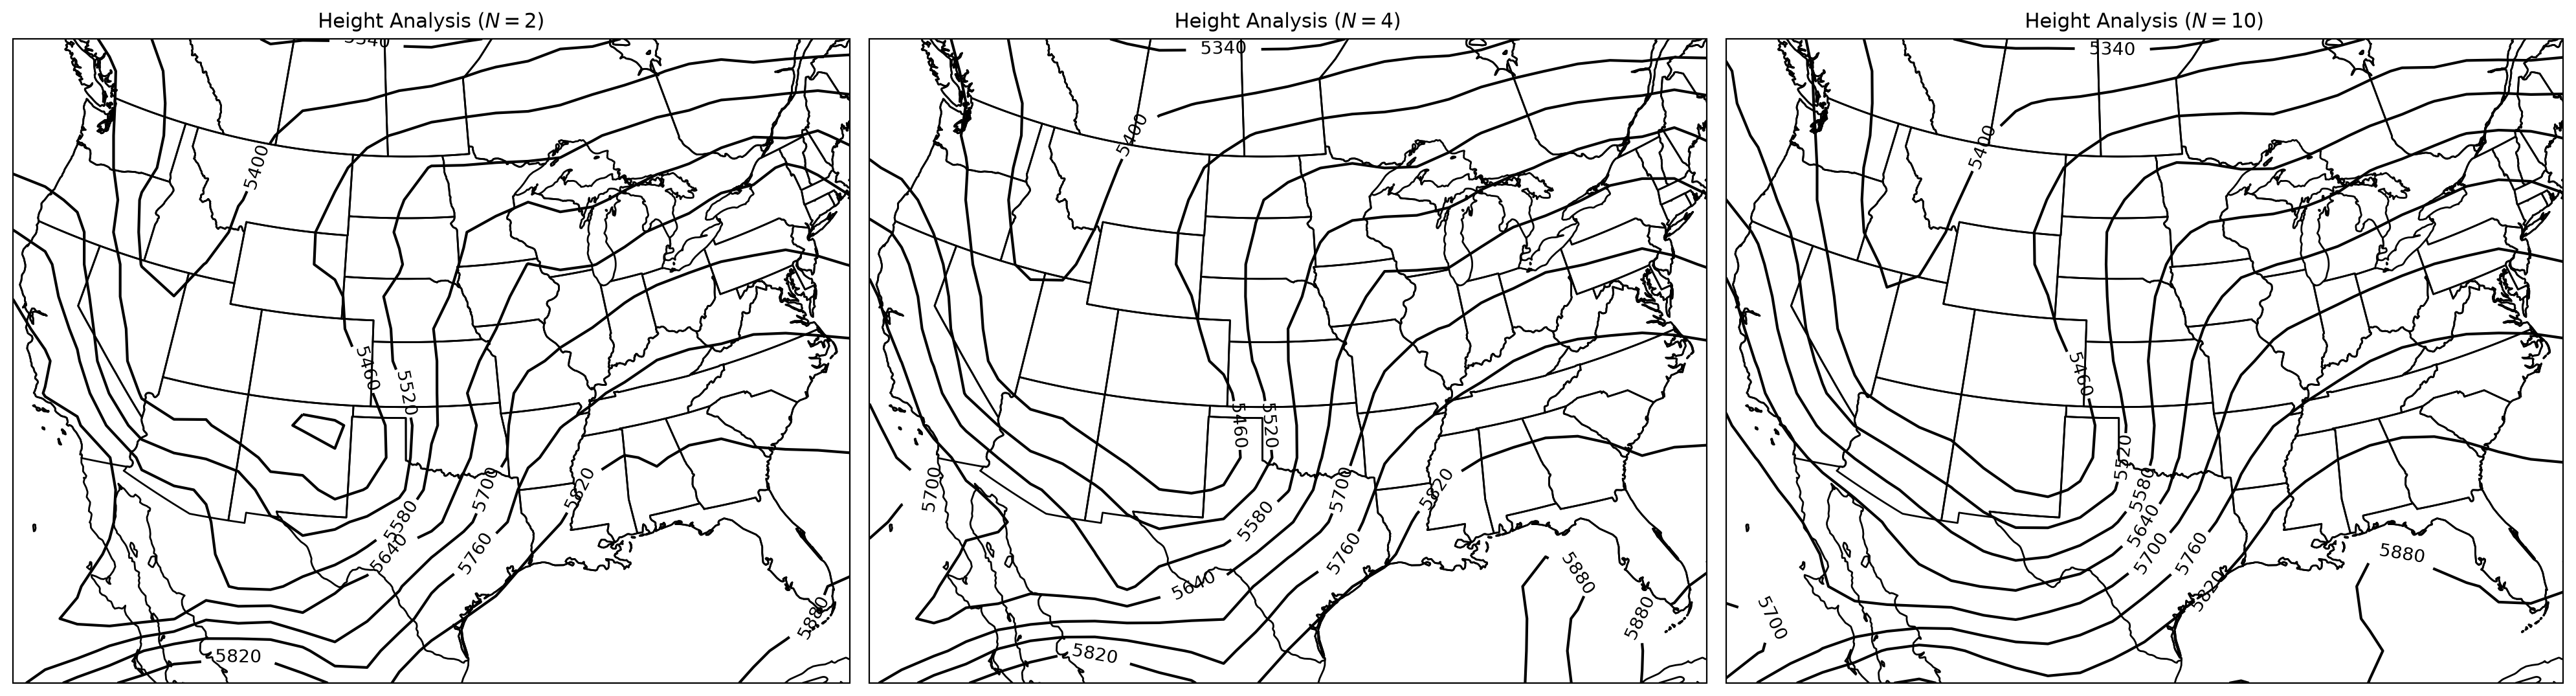

In [10]:
# Now to plot everything beginning with analysis fields

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=lambda_0, central_latitude=90, true_scale_latitude=phi_0, globe=globe)

fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=200, subplot_kw={'projection': proj})

analyses = [analysis_grids[2], analysis_grids[4], analysis_grids[10]]
titles = [
    'Height Analysis ($N = 2$)',
    'Height Analysis ($N = 4$)',
    'Height Analysis ($N = 10$)'
]
levels = np.arange(4800, 6000, 60)

for ax, analysis, title in zip(axes, analyses, titles):
    ax.add_feature(cfeature.STATES)
    ax.add_feature(cfeature.COASTLINE)
    
    cs1 = ax.contour(grid_y_map / m / 100, -grid_x_map / m / 100, analysis, colors='k', levels=levels, transform=proj)
    ax.clabel(cs1, levels=levels, fmt='%d')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('statistical_analysis_all_N.png', dpi=300, bbox_inches='tight')
plt.show()

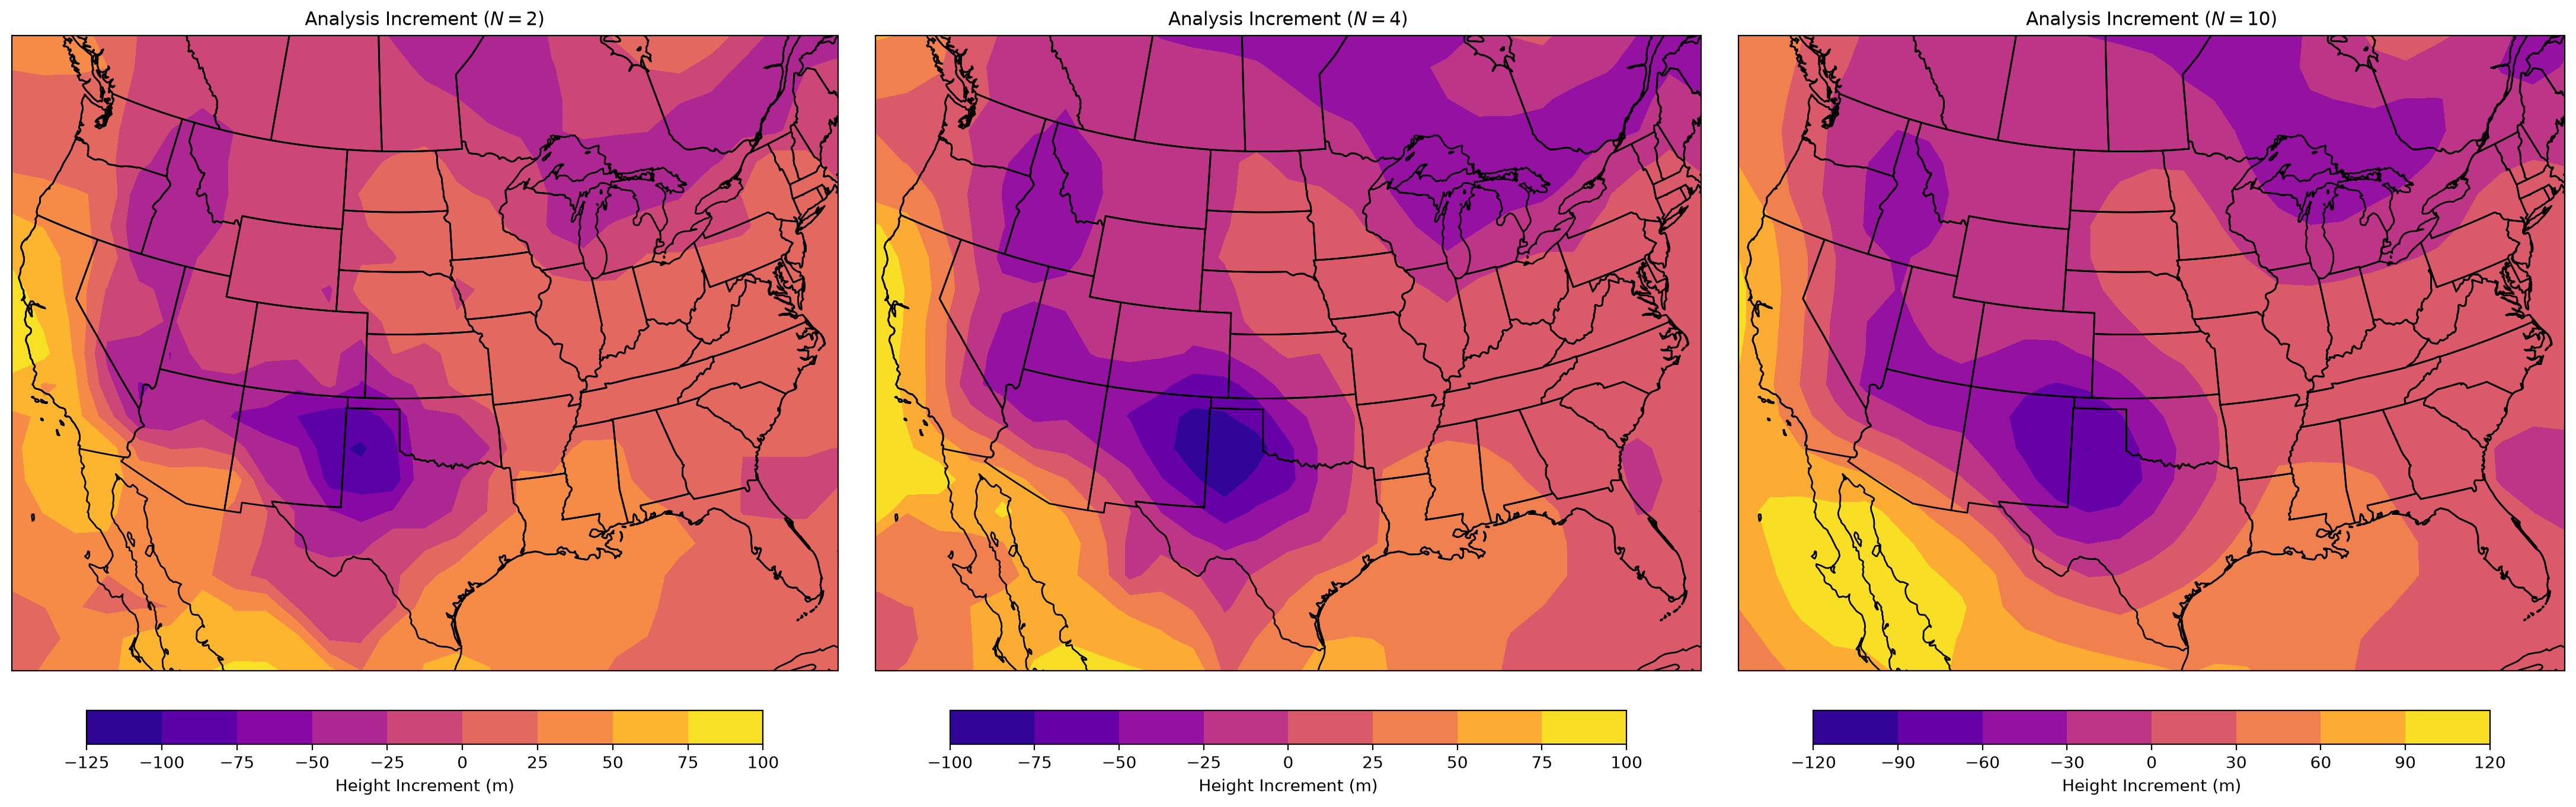

In [11]:
# Plot for analysis increment fields

fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=200, subplot_kw={'projection': proj})

increments = [increment_grids[2], increment_grids[4], increment_grids[10]]
increment_titles = [
    'Analysis Increment ($N = 2$)',
    'Analysis Increment ($N = 4$)',
    'Analysis Increment ($N = 10$)'
]

for ax, inc, title in zip(axes, increments, increment_titles):
    ax.add_feature(cfeature.STATES)
    ax.add_feature(cfeature.COASTLINE)
    
    cf = ax.contourf(grid_y_map / m / 100, -grid_x_map / m / 100, inc, cmap='plasma', transform=proj)
    fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8, label='Height Increment (m)')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('analysis_increments_all_N.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Now for Analysis differences and RMS

def bilinear_interpolate_2d(x_1d, y_1d, grid_2d, px, py):
    if px < x_1d[0] or px > x_1d[-1] or py < y_1d[0] or py > y_1d[-1]:
        return None
    i = np.searchsorted(x_1d, px) -1
    j = np.searchsorted(y_1d, py) -1
    i = np.clip(i, 0, len(x_1d) - 2)
    j = np.clip(j, 0, len(y_1d) - 2)
        
    x1, x2 = x_1d[i], x_1d[i+1]
    y1, y2 = y_1d[j], y_1d[j+1]
        
    q11 = grid_2d[i, j]
    q21 = grid_2d[i + 1, j]
    q12 = grid_2d[i, j + 1]
    q22 = grid_2d[i + 1, j + 1]
        
    r1 = ((x2 - px) / (x2 - x1)) * q11 + ((px - x1) / (x2 - x1)) * q21
    r2 = ((x2 - px) / (x2 - x1)) * q12 + ((px - x1) / (x2 - x1)) * q22
    val = ((y2 - py) / (y2 - y1)) * r1 + ((py - y1) / (y2 - y1)) * r2
    return val

In [13]:
# Analysis Differences and RMS

rms_summary = {}

for N in N_values:
    analysis_grid = analysis_grids[N]
    increment_grid = increment_grids[N]
    
    forward_interp_values = np.zeros(len(obs_x))
    for k in range(len(obs_x)):
        ox = obs_x[k]
        oy = obs_y[k]
        
        # Bilinear interpolation for obs stations within domain
        if (grid_x_1d[0] <= ox <= grid_x_1d[-1]) and (grid_y_1d[0] <= oy <= grid_y_1d[-1]):
            val = bilinear_interpolate_2d(grid_x_1d, grid_y_1d, analysis_grid, ox, oy)
            if val is not None:
                forward_interp_values[k] = val
            else:
                # Fallback to one-pass Barnes scheme if interpolation returns None
                d_sq = (grid_x_map - ox)**2 + (grid_y_map - oy)**2
                valid_mask = d_sq <= re**2
                if np.any(valid_mask):
                    d_sq_valid = d_sq[valid_mask]
                    grid_values_valid = analysis_grid[valid_mask]
                    weights = np.exp(-d_sq_valid / Kd)
                    forward_interp_values[k] = np.sum(weights * grid_values_valid) / np.sum(weights)
                else:
                    min_idx = np.argmin(d_sq)
                    forward_interp_values[k] = analysis_grid.flatten()[min_idx]
        else:
            # 2. One-pass Barnes scheme for observation stations outside the grid domain[cite: 41]
            d_sq = (grid_x_map - ox)**2 + (grid_y_map - oy)**2
            valid_mask = d_sq <= re**2
            if np.any(valid_mask):
                d_sq_valid = d_sq[valid_mask]
                grid_values_valid = analysis_grid[valid_mask]
                weights = np.exp(-d_sq_valid / Kd)
                forward_interp_values[k] = np.sum(weights * grid_values_valid) / np.sum(weights)
            else:
                min_idx = np.argmin(d_sq)
                forward_interp_values[k] = analysis_grid.flatten()[min_idx]
    # Analysis diff at each station
    station_diffs = forward_interp_values - obs_hgt
    
    #RMS Diffs between analysis and obs
    rms_value = np.sqrt(np.mean(station_diffs**2))
    rms_summary[N] = rms_value
    print(f"RMS for N = {N}: {rms_value:.4f} m")
    
    # Saving each file
    np.savetxt(f'analysis_N{N}.txt', analysis_grid, fmt='%.4f', header=f'Statistical Objective Analysis Raw Heights (N={N})')
    np.savetxt(f'analysis_increment_N{N}.txt', increment_grid, fmt='%.4f', header=f'Analysis Increment Raw Values (N={N})')
    np.savetxt(f'station_diffs_N{N}.txt', station_diffs, fmt='%.4f', header=f'Analysis Differences (Analysis - Obs) at Stations (N={N})')

# Saves RMS Summary
with open('rms_summary.txt', 'w') as f:
    f.write("N_value\tRMS_Difference (m)\n")
    for N, rms in rms_summary.items():
        f.write(f"{N}\t{rms:.6f}\n")

RMS for N = 2: 117.7747 m
RMS for N = 4: 119.2595 m
RMS for N = 10: 119.1229 m


In [14]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.

    In each height analysis, there is a pronounced trough over the western US into Texas. There is a ridge over the eastern US. In each analysis there 
    is a difference in what is shown between N = 2 and the other 2 analyses. It shows a closed contour over New Mexico signifying the location of the 
    low. N = 10 and N = 4 are very similar, but N = 4 has the 5700 line in Gulf of California north of where the N = 10 analysis has it. N = 4 has a 
    different 5880 line in the Gulf of Mexico. The analysis increment shows a similar pattern to the height analysis. N = 2 has different look to N = 4 
    and N = 10. The difference is over western Texas and the Gulf of California and Gulf of Mexico. Just off the east coast in Northern Florida there is
    a difference in each analysis increment. These differences coincide with differences on the height analysis.

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?

    Each of the Gulf of California and Gulf of Mexico are difference in each analysis. There are slight changes to the contour shape in each analysis
    that may show some smoothing happening as we go up in observations used at each analysis point. This smoothing happens since some anaysis points may
    not have enough observations to resolve leaving only the background available to fill in. The analysis does get better at the points where there are
    enough observations to resolve the data. The N = 2 is a worse analysis than the analyses with more observations included. This makes sense as more
    observations included means a better analysis due to less overall error.

3 - What happens as you increase the number of points considered for the analysis?  Is this 
    desirable?  Why or why not?

    As the number of points increase, the analysis improves only in locations that have enough observations to resolve. This can be desirable up until
    points begin running out of observations to satisfy the N value. For example, we used N = 4 and N = 10. There is a chance N = 4 is better than N = 10
    since analysis points may not have enough observations to satisfy the N value. This is where we run into the undesirable side. Many N values have to
    be tested to see where we run into a lack of ovservations available for analysis points.
    
'''

'\n1 - Describe the general features that you see in your contoured analyses.\n    \n\n2 - Describe the differences that you see in your contoured analyses.  \n    Does one analysis seem to be smoother than the other?  If so, what would cause this?\n    \n\n3 - What happens as you increase the number of points considered for the analysis?  Is this \n    desirable?  Why or why not?\n    \n'